# Task 3: Reproducing MuCoCo and building MuReCo
Akwasi Asare, PhD assessment for Prof. Ezekiel Soremekun (SUTD)

This notebook has the two parts of Task 3. In Part 1, I set up the MuCoCo code and data and rerun its CruxEval output-prediction experiment. In Part 2, I run my MuReCo prototype, which builds on MuCoCo's mutation code and also checks the model's step-by-step reasoning.

I ran everything on a Colab A100 (80 GB). The MuReCo code is loaded from my Google Drive (`mureco.zip`).

Order of the notebook:
0. Setup
1. Tests of the parser and the pipeline (no model needed)
2. Part 1: MuCoCo's experiment with Qwen2.5-Coder-14B, the model used in the paper
3. Part 2: MuReCo with Qwen2.5-Coder-1.5B and 7B
4. Checking the raw model answers
5. Part 2b: a small reasoning model (DeepSeek-R1-Distill-Qwen-1.5B)
6. A walkthrough of one example, and saving the results

Note: after this run I fixed one more case in the answer parser (an `OUTPUT:` label written in the middle of a sentence) and rescored the saved answers with `scripts/rescore.py`. The final numbers in my slides come from that rescoring. The 7B results did not change.

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB


## 0. Setup
I clone the MuCoCo repository, mount my Drive, unzip the MuReCo code and install the packages.

In [ ]:
%cd /content
!rm -rf /content/mureco
![ -d /content/mucoco ] || git clone -q --depth 1 https://github.com/mucoco-tester/mucoco-tester.github.io.git /content/mucoco
from google.colab import drive
drive.mount('/content/drive')
!unzip -q -o /content/drive/MyDrive/mureco.zip -d /content && ls /content/mureco
%env MUCOCO_DIR=/content/mucoco
%cd /content/mureco
!pip -q install -U "transformers>=4.44" accelerate bitsandbytes

/content
Mounted at /content/drive
mureco	notebooks  README.md  scripts
env: MUCOCO_DIR=/content/mucoco
/content/mureco


## 1. Tests
Before running any model, I check that the answer parser can read different answer formats, and that the pipeline gives the expected results with a perfect test model (0% inconsistency) and with injected trace errors (all of them detected).

In [ ]:
!python scripts/parser_test.py | tail -1
!python scripts/selftest.py 2>&1 | grep -v DEBUG | tail -4

PARSER TESTS PASSED
Built 40 tasks; skipped: {'no traceable variable': 32}
Oracle model: answer inc. 0.0% (0/193) | reasoning inc. 0.0% (0/193) | trace acc. 100.0% (40/40)
Corrupting oracle: answer inc. 0.0% (0/193) | reasoning inc. 26.4% (51/193) | injected 51, detected 51
SELF-TEST PASSED


## 2. Part 1: MuCoCo's experiment
This uses MuCoCo's own code: the CruxEval data from the repository, its 11 mutation operators, its zero-shot prompt, and its answer processing and correctness check. I used Qwen2.5-Coder-14B-Instruct because it is the model in the paper (Table 4).

In [ ]:
!python scripts/run_mucoco_demo.py --model Qwen/Qwen2.5-Coder-14B-Instruct --n 50 --batch 32 --out results_part1 2>&1 | grep -v DEBUG

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
50 tasks, 215 MuCoCo test cases (mutants)
Loading weights: 100%|██████████| 579/579 [00:09<00:00, 59.82it/s]
## MuCoCo reproduction: Qwen/Qwen2.5-Coder-14B-Instruct, CruxEval output prediction, 50 tasks

| Mutation type | Inconsistency % | Mutant accuracy % |
|---|---|---|
| Lexical | 13.01 (16/123) | 56.10 (69/123) |
| Syntactic | 10.53 (4/38) | 47.37 (18/38) |
| Logical | 24.07 (13/54) | 40.74 (22/54) |
| All | 15.35 (33/215) | 50.70 (109/215) |

Original-program accuracy: 56.00% (28/50); invalid answers: originals 4/50, mutants 21/215

| Operator | Inconsistency % | Mutant accuracy % |
|---|---|---|
| random | 18.00 (9/50) | 60.00 (30/50) |
| sequential | 14.00 (7/50) | 60.00 (30/50) |
| literal_format | 0.00 (0/23) | 39.13 (9/23) |
| for2while | 10.53 (2/19) | 42.11 (8/19) |
| for2enumerate | 10.53 (2/19) | 52.63 (10/19) |
| demorgan | 0.00 (0/4) | 75.00 (3/4) |
| boolean_literal | 0.00 (0/4) | 75.00 (3/4) |
| commuta

The paper's Table 6 can also be checked without a GPU: download the replication package from
[Figshare](https://figshare.com/articles/journal_contribution/_b_MuCoCo_Code_Consistency_Testing_Framework_Replication_Package_b_/30402541),
put it in `mucoco/MuCoCo_results/MuCoCo_experiment_results`, and run `mucoco/MuCoCo_results/notebooks/RQ1_results_aggregation.ipynb`.

## 3. Part 2: MuReCo
For each program I use the original, each single mutation and every valid pair of mutations. The model has to give a trace of up to two variables and the output, and I compare the trace with the real execution. I also rerun each original twice to see how often the answer changes by chance.

In [ ]:
!python scripts/run_mureco.py --models Qwen/Qwen2.5-Coder-1.5B-Instruct Qwen/Qwen2.5-Coder-7B-Instruct --n 60 --batch 32 --max-new-tokens 768 --out results_part2 2>&1 | grep -v DEBUG

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Built 60 tasks; skipped: {'no traceable variable': 54}
Suite: 60 tasks, 354 programs (294 mutants)
Loading weights: 100%|██████████| 338/338 [00:00<00:00, 351.35it/s]
[MuReCo] Qwen/Qwen2.5-Coder-1.5B-Instruct: 354 prompts for 60 tasks
[MuReCo] generation done in 487s
## Qwen/Qwen2.5-Coder-1.5B-Instruct  (60 CruxEval tasks)

| Measure | Value |
|---|---|
| Parsing: answers with no readable output | 62.7% (222/354) |
| Parsing: answers with all traces readable | 40.4% (143/354) |
| Original: answer accuracy | 18.3% (11/60) |
| Original: trace accuracy | 3.3% (2/60) |
| Original: right answer, wrong reasoning | 81.8% (9/11) |
| Single mutations: answer inconsistency (MuCoCo) | 50.3% (88/175) |
| Single mutations: reasoning inconsistency, answers agree (MuReCo) | 34.8% (8/23) |
| Pairs of mutations: answer inconsistency (MuCoCo) | 53.8% (64/119) |
| Pairs of mutations: reasoning inconsistency, answers agree (MuReCo) | 11.1% (

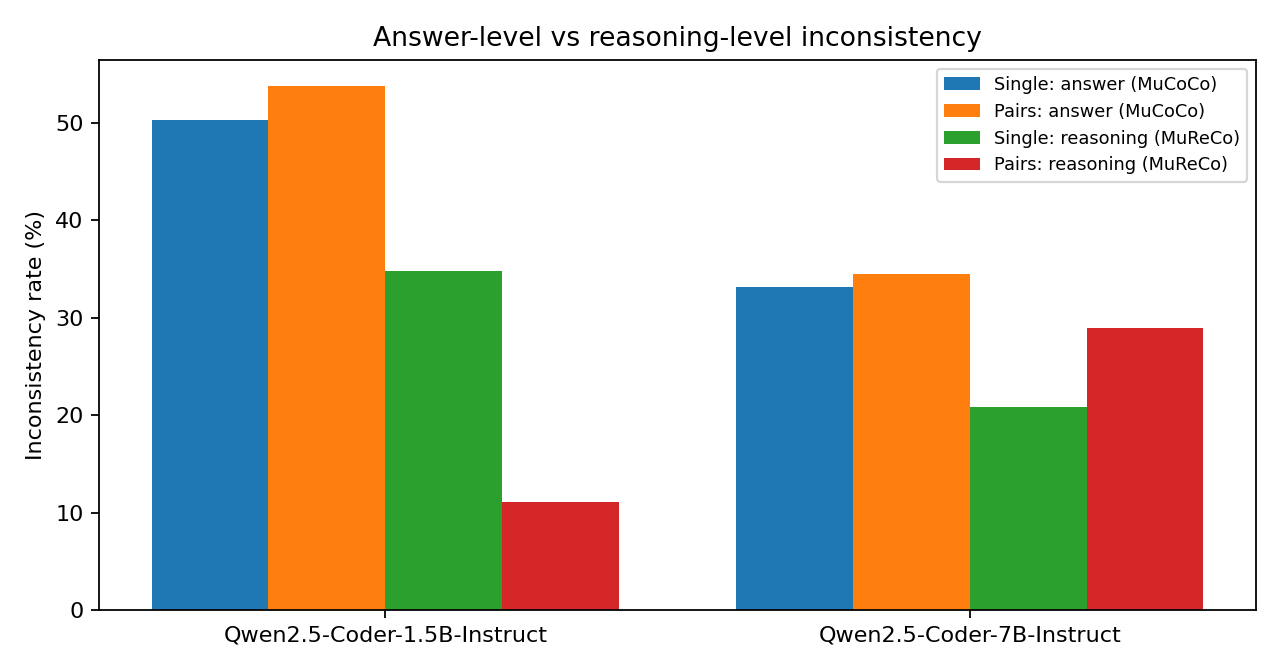

# MuReCo prototype results

## Qwen/Qwen2.5-Coder-1.5B-Instruct  (60 CruxEval tasks)

| Measure | Value |
|---|---|
| Parsing: answers with no readable output | 62.7% (222/354) |
| Parsing: answers with all traces readable | 40.4% (143/354) |
| Original: answer accuracy | 18.3% (11/60) |
| Original: trace accuracy | 3.3% (2/60) |
| Original: right answer, wrong reasoning | 81.8% (9/11) |
| Single mutations: answer inconsistency (MuCoCo) | 50.3% (88/175) |
| Single mutations: reasoning inconsistency, answers agree (MuReCo) | 34.8% (8/23) |
| Pairs of mutations: answer inconsistency (MuCoCo) | 53.8% (64/119) |
| Pairs of mutations: reasoning inconsistency, answers agree (MuReCo) | 11.1% (1/9) |
| All mutants: answer inconsistency (MuCoCo) | 51.7% (152/294) |
| All mutants: reasoning inconsistency, answers agree (MuReCo) | 28.1% (9/32) |
| Hidden pair failures (pair fails, both singles pass) | 7.7% (5/65) |
| Noise: rerun flip rate on originals | 7.5% (9/120) |

| Variant | Pairs | Answer inc. | Reasoning inc. (answers agree) | Mutant trace acc. |
|---|---|---|---|---|
| constant_unfold | 14 | 50.0% (7/14) | 0.0% (0/1) | 0.0% (0/14) |
| demorgan | 2 | 100.0% (2/2) | n/a | 0.0% (0/2) |
| for2while | 39 | 46.2% (18/39) | 66.7% (2/3) | 2.6% (1/39) |
| random | 60 | 48.3% (29/60) | 40.0% (4/10) | 8.3% (5/60) |
| sequential | 60 | 53.3% (32/60) | 22.2% (2/9) | 5.0% (3/60) |
| for2while+constant_unfold | 7 | 28.6% (2/7) | n/a | 0.0% (0/7) |
| for2while+demorgan | 2 | 100.0% (2/2) | n/a | 0.0% (0/2) |
| random+constant_unfold | 14 | 78.6% (11/14) | n/a | 0.0% (0/14) |
| random+demorgan | 2 | 100.0% (2/2) | n/a | 0.0% (0/2) |
| random+for2while | 39 | 46.2% (18/39) | 0.0% (0/3) | 7.7% (3/39) |
| sequential+constant_unfold | 14 | 78.6% (11/14) | n/a | 7.1% (1/14) |
| sequential+demorgan | 2 | 0.0% (0/2) | 50.0% (1/2) | 0.0% (0/2) |
| sequential+for2while | 39 | 46.2% (18/39) | 0.0% (0/4) | 10.3% (4/39) |

### Examples: answers agree, reasoning does not

### CruxEval_702 (sample_702), mutation: random
Original program:
```python
def f(nums):
    count = len(nums)
    for i in range(len(nums) - 1, -1, -1):
        nums.insert(i, nums.pop(0))
    return nums
```
Mutated program (random):
```python
def afZLcQ(gXwpbb):
    count = len(gXwpbb)
    for i in range(len(gXwpbb) - 1, -1, -1):
        gXwpbb.insert(i, gXwpbb.pop(0))
    return gXwpbb
```
Call input: `[0, -5, -4]`; expected output `[-4, -5, 0]`

| | Answer | Trace |
|---|---|---|
| Ground truth | `[-4, -5, 0]` | `{'i': ['2', '1', '0'], 'nums': ['[0, -5, -4]', '[-5, -4, 0]', '[-4, -5, 0]']}` |
| Model on original | `None` (invalid) | `{'i': ['2', '1', '0'], 'nums': ['0', '-5', '-4', '-5', '-4']}` |
| Model on mutant | `None` (invalid) | `{'i': ['2', '1', '0'], 'nums': ['0', '-5', '0']}` |


### CruxEval_702 (sample_702), mutation: for2while
Original program:
```python
def f(nums):
    count = len(nums)
    for i in range(len(nums) - 1, -1, -1):
        nums.insert(i, nums.pop(0))
    return nums
```
Mutated program (for2while):
```python
def f(nums):
    count = len(nums)
    loop_var0 = len(nums) - 1
    while loop_var0 > -1:
        i = loop_var0
        nums.insert(i, nums.pop(0))
        loop_var0 += -1
    return nums
```
Call input: `[0, -5, -4]`; expected output `[-4, -5, 0]`

| | Answer | Trace |
|---|---|---|
| Ground truth | `[-4, -5, 0]` | `{'i': ['2', '1', '0'], 'nums': ['[0, -5, -4]', '[-5, -4, 0]', '[-4, -5, 0]']}` |
| Model on original | `None` (invalid) | `{'i': ['2', '1', '0'], 'nums': ['0', '-5', '-4', '-5', '-4']}` |
| Model on mutant | `None` (invalid) | `{'i': ['2', '1', '0'], 'nums': ['0', '-5', '-4', '0']}` |


### CruxEval_614 (sample_614), mutation: random
Original program:
```python
def f(text, substr, occ):
    n = 0
    while True:
        i = text.rfind(substr)
        if i == -1:
            break
        elif n == occ:
            return i
        else:
            n += 1
            text = text[:i]
    return -1
```
Mutated program (random):
```python
def eMRfGLcrJePt(wrpPmDHQbGea, jTEQykdeLF, eJnjbwX):
    n = 0
    while True:
        i = wrpPmDHQbGea.rfind(jTEQykdeLF)
        if i == -1:
            break
        elif n == eJnjbwX:
            return i
        else:
            n += 1
            wrpPmDHQbGea = wrpPmDHQbGea[:i]
    return -1
```
Call input: `'zjegiymjc', 'j', 2`; expected output `-1`

| | Answer | Trace |
|---|---|---|
| Ground truth | `-1` | `{'n': ['0', '1', '2'], 'i': ['7', '1', '-1']}` |
| Model on original | `-1` (correct) | `{'n': ['0', '1', '2'], 'i': ['7', '4', '-1']}` |
| Model on mutant | `-1` (correct) | `{'n': ['0'], 'i': ['-1']}` |


## Qwen/Qwen2.5-Coder-7B-Instruct  (60 CruxEval tasks)

| Measure | Value |
|---|---|
| Parsing: answers with no readable output | 0.8% (3/354) |
| Parsing: answers with all traces readable | 98.9% (350/354) |
| Original: answer accuracy | 38.3% (23/60) |
| Original: trace accuracy | 16.7% (10/60) |
| Original: right answer, wrong reasoning | 60.9% (14/23) |
| Single mutations: answer inconsistency (MuCoCo) | 33.1% (58/175) |
| Single mutations: reasoning inconsistency, answers agree (MuReCo) | 20.9% (24/115) |
| Pairs of mutations: answer inconsistency (MuCoCo) | 34.5% (41/119) |
| Pairs of mutations: reasoning inconsistency, answers agree (MuReCo) | 28.9% (22/76) |
| All mutants: answer inconsistency (MuCoCo) | 33.7% (99/294) |
| All mutants: reasoning inconsistency, answers agree (MuReCo) | 24.1% (46/191) |
| Hidden pair failures (pair fails, both singles pass) | 9.5% (6/63) |
| Noise: rerun flip rate on originals | 1.7% (2/120) |

| Variant | Pairs | Answer inc. | Reasoning inc. (answers agree) | Mutant trace acc. |
|---|---|---|---|---|
| constant_unfold | 14 | 42.9% (6/14) | 25.0% (2/8) | 7.1% (1/14) |
| demorgan | 2 | 0.0% (0/2) | 100.0% (2/2) | 0.0% (0/2) |
| for2while | 39 | 25.6% (10/39) | 25.0% (7/28) | 17.9% (7/39) |
| random | 60 | 40.0% (24/60) | 13.9% (5/36) | 20.0% (12/60) |
| sequential | 60 | 30.0% (18/60) | 19.5% (8/41) | 18.3% (11/60) |
| for2while+constant_unfold | 7 | 28.6% (2/7) | 60.0% (3/5) | 0.0% (0/7) |
| for2while+demorgan | 2 | 0.0% (0/2) | 100.0% (2/2) | 0.0% (0/2) |
| random+constant_unfold | 14 | 35.7% (5/14) | 22.2% (2/9) | 7.1% (1/14) |
| random+demorgan | 2 | 0.0% (0/2) | 100.0% (2/2) | 0.0% (0/2) |
| random+for2while | 39 | 33.3% (13/39) | 24.0% (6/25) | 17.9% (7/39) |
| sequential+constant_unfold | 14 | 42.9% (6/14) | 25.0% (2/8) | 7.1% (1/14) |
| sequential+demorgan | 2 | 0.0% (0/2) | 50.0% (1/2) | 0.0% (0/2) |
| sequential+for2while | 39 | 38.5% (15/39) | 17.4% (4/23) | 17.9% (7/39) |

### Examples: answers agree, reasoning does not

### CruxEval_244 (sample_244), mutation: for2while
Original program:
```python
def f(text, symbols):
    count = 0
    if symbols:
        for i in symbols:
            count += 1
        text = text * count
    return text.rjust(len(text) + count*2)[:-2]
```
Mutated program (for2while):
```python
def f(text, symbols):
    count = 0
    if symbols:
        loop_var0 = 0
        while loop_var0 < len(symbols):
            i = symbols[loop_var0]
            count += 1
            loop_var0 += 1
        text = text * count
    return text.rjust(len(text) + count * 2)[:-2]
```
Call input: `'', 'BC1ty'`; expected output `'        '`

| | Answer | Trace |
|---|---|---|
| Ground truth | `'        '` | `{'count': ['0', '1', '2', '3', '4', '5'], 'i': ["'B'", "'C'", "'1'", "'t'", "'y'"]}` |
| Model on original | `''` (incorrect) | `{'count': ['0', '3'], 'i': ["'B'", "'C'", "'1'"]}` |
| Model on mutant | `''` (incorrect) | `{'count': ['0', '1', '2', '3'], 'i': ["'B'", "'C'", "'1'", "'t'"]}` |


### CruxEval_244 (sample_244), mutation: sequential+constant_unfold
Original program:
```python
def f(text, symbols):
    count = 0
    if symbols:
        for i in symbols:
            count += 1
        text = text * count
    return text.rjust(len(text) + count*2)[:-2]
```
Mutated program (sequential+constant_unfold):
```python
def generic_function1(var1, var2):
    count = 0
    if var2:
        for i in var2:
            count += 1
        var1 = var1 * count
    return var1.rjust(len(var1) + count * (2 * 1))[:-(2 * 1)]
```
Call input: `'', 'BC1ty'`; expected output `'        '`

| | Answer | Trace |
|---|---|---|
| Ground truth | `'        '` | `{'count': ['0', '1', '2', '3', '4', '5'], 'i': ["'B'", "'C'", "'1'", "'t'", "'y'"]}` |
| Model on original | `''` (incorrect) | `{'count': ['0', '3'], 'i': ["'B'", "'C'", "'1'"]}` |
| Model on mutant | `''` (incorrect) | `{'count': ['0', '1', '2'], 'i': ["'B'", "'C'", "'1'"]}` |


### CruxEval_244 (sample_244), mutation: for2while+constant_unfold
Original program:
```python
def f(text, symbols):
    count = 0
    if symbols:
        for i in symbols:
            count += 1
        text = text * count
    return text.rjust(len(text) + count*2)[:-2]
```
Mutated program (for2while+constant_unfold):
```python
def f(text, symbols):
    count = 0
    if symbols:
        loop_var0 = 0
        while loop_var0 < len(symbols):
            i = symbols[loop_var0]
            count += 1
            loop_var0 += 1
        text = text * count
    return text.rjust(len(text) + count * (2 * 1))[:-(2 * 1)]
```
Call input: `'', 'BC1ty'`; expected output `'        '`

| | Answer | Trace |
|---|---|---|
| Ground truth | `'        '` | `{'count': ['0', '1', '2', '3', '4', '5'], 'i': ["'B'", "'C'", "'1'", "'t'", "'y'"]}` |
| Model on original | `''` (incorrect) | `{'count': ['0', '3'], 'i': ["'B'", "'C'", "'1'"]}` |
| Model on mutant | `''` (incorrect) | `{'count': ['0', '1', '2', '3'], 'i': ["'B'", "'C'", "'1'", "'t'"]}` |



In [ ]:
from IPython.display import Markdown, Image, display
display(Image('results_part2/inconsistency_rates.png'))
display(Markdown(open('results_part2/REPORT.md').read()))

## 4. Checking the raw answers
Some scores were low, so I wanted to see whether the problem was the model or my parser. This prints how many answers could be read, and three raw answers per model with their scores.

In [ ]:
import json, glob, textwrap
for f in sorted(glob.glob('results_part2*/*_summary.json')):
    s = json.load(open(f)); p = s['parsing']
    print(f"{s['model']}: no readable output {p['invalid_output_rate'][0]:.1f}%, all traces readable {p['trace_parsed_rate'][0]:.1f}%")
for f in sorted(glob.glob('results_part2*/*_records.jsonl')):
    print('\n' + '=' * 100 + '\n' + f)
    for line in open(f).readlines()[:3]:
        r = json.loads(line); o = r['variants']['original']
        print(f"\n--- {r['task']}  tracked {r['tracked']}  expected {r['expected']}")
        print('ground truth:', r['gt_trace'])
        print('RAW MODEL ANSWER:\n' + textwrap.indent(o['raw'][-900:], '    '))
        print(f"scored -> output={o['output']} ({o['outcome']}), traces={o['traces']}, trace correct={o['trace_correct']}")

Qwen/Qwen2.5-Coder-1.5B-Instruct: no readable output 62.7%, all traces readable 40.4%
Qwen/Qwen2.5-Coder-7B-Instruct: no readable output 0.8%, all traces readable 98.9%

results_part2/Qwen2.5-Coder-1.5B-Instruct_records.jsonl

--- CruxEval_244  tracked ['count', 'i']  expected '        '
ground truth: {'count': ['0', '1', '2', '3', '4', '5'], 'i': ["'B'", "'C'", "'1'", "'t'", "'y'"]}
RAW MODEL ANSWER:
    tyBC1tyBC1tyBC1tyBC1ty'`.

    5. **Fourth Iteration (i = 't')**:
       - `count` is incremented to `4`.
       - `text` is updated to `'BC1tyBC1tyBC1tyBC1tyBC1ty' * 4`, which results in `'BC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyBC1tyB

## 5. Part 2b: a reasoning model
DeepSeek-R1-Distill-Qwen-1.5B thinks before it answers, so I gave it a larger token budget. Answers that stop in the middle of the thinking count as invalid.

In [ ]:
!python scripts/run_mureco.py --models deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B --n 20 --max-new-tokens 4096 --batch 24 --reruns 1 --out results_part2_reasoning 2>&1 | grep -v DEBUG
from IPython.display import Markdown, display
display(Markdown(open('results_part2_reasoning/REPORT.md').read()))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Built 20 tasks; skipped: {'no traceable variable': 14}
Suite: 20 tasks, 124 programs (104 mutants)
Loading weights: 100%|██████████| 339/339 [00:01<00:00, 322.39it/s]
[MuReCo] deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B: 124 prompts for 20 tasks
[MuReCo] generation done in 1214s
## deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B  (20 CruxEval tasks)

| Measure | Value |
|---|---|
| Parsing: answers with no readable output | 49.2% (61/124) |
| Parsing: answers with all traces readable | 41.9% (52/124) |
| Original: answer accuracy | 20.0% (4/20) |
| Original: trace accuracy | 5.0% (1/20) |
| Original: right answer, wrong reasoning | 25.0% (1/4) |
| Single mutations: answer inconsistency (MuCoCo) | 51.7% (31/60) |
| Single mutations: reasoning inconsistency, answers agree (MuReCo) | 14.3% (1/7) |
| Pairs of mutations: answer inconsistency (MuCoCo) | 45.5% (20/44) |
| Pairs of mutations: reasoning inconsistency, answers agree (MuReC

# MuReCo prototype results

## deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B  (20 CruxEval tasks)

| Measure | Value |
|---|---|
| Parsing: answers with no readable output | 49.2% (61/124) |
| Parsing: answers with all traces readable | 41.9% (52/124) |
| Original: answer accuracy | 20.0% (4/20) |
| Original: trace accuracy | 5.0% (1/20) |
| Original: right answer, wrong reasoning | 25.0% (1/4) |
| Single mutations: answer inconsistency (MuCoCo) | 51.7% (31/60) |
| Single mutations: reasoning inconsistency, answers agree (MuReCo) | 14.3% (1/7) |
| Pairs of mutations: answer inconsistency (MuCoCo) | 45.5% (20/44) |
| Pairs of mutations: reasoning inconsistency, answers agree (MuReCo) | 33.3% (1/3) |
| All mutants: answer inconsistency (MuCoCo) | 49.0% (51/104) |
| All mutants: reasoning inconsistency, answers agree (MuReCo) | 20.0% (2/10) |
| Hidden pair failures (pair fails, both singles pass) | 19.0% (4/21) |
| Noise: rerun flip rate on originals | 30.0% (6/20) |

| Variant | Pairs | Answer inc. | Reasoning inc. (answers agree) | Mutant trace acc. |
|---|---|---|---|---|
| constant_unfold | 7 | 57.1% (4/7) | 100.0% (1/1) | 0.0% (0/7) |
| for2while | 13 | 53.8% (7/13) | 0.0% (0/2) | 15.4% (2/13) |
| random | 20 | 50.0% (10/20) | 0.0% (0/1) | 5.0% (1/20) |
| sequential | 20 | 50.0% (10/20) | 0.0% (0/3) | 0.0% (0/20) |
| for2while+constant_unfold | 4 | 0.0% (0/4) | n/a | 0.0% (0/4) |
| random+constant_unfold | 7 | 57.1% (4/7) | 100.0% (1/1) | 0.0% (0/7) |
| random+for2while | 13 | 46.2% (6/13) | 0.0% (0/2) | 7.7% (1/13) |
| sequential+constant_unfold | 7 | 42.9% (3/7) | n/a | 14.3% (1/7) |
| sequential+for2while | 13 | 53.8% (7/13) | n/a | 0.0% (0/13) |

### Examples: answers agree, reasoning does not

### CruxEval_545 (sample_545), mutation: constant_unfold
Original program:
```python
def f(array):
    result = []
    index = 0
    while index < len(array):
        result.append(array.pop())
        index += 2
    return result
```
Mutated program (constant_unfold):
```python
def f(array):
    result = []
    index = 0
    while index < len(array):
        result.append(array.pop())
        index += 2 * 1
    return result
```
Call input: `[8, 8, -4, -9, 2, 8, -1, 8]`; expected output `[8, -1, 8]`

| | Answer | Trace |
|---|---|---|
| Ground truth | `[8, -1, 8]` | `{'result': ['[]', '[8]', '[8, -1]', '[8, -1, 8]'], 'index': ['0', '2', '4', '6']}` |
| Model on original | `'<return value>'` (incorrect) | `{'result': ['8', '-4', '2', '-1'], 'index': ['0', '2', '4', '6']}` |
| Model on mutant | `'<return value>'` (incorrect) | `{'result': ['8', '-1', '8'], 'index': ['0', '2', '4', '6', '8']}` |


### CruxEval_545 (sample_545), mutation: random+constant_unfold
Original program:
```python
def f(array):
    result = []
    index = 0
    while index < len(array):
        result.append(array.pop())
        index += 2
    return result
```
Mutated program (random+constant_unfold):
```python
def afZLcQ(gXwpbb):
    result = []
    index = 0
    while index < len(gXwpbb):
        result.append(gXwpbb.pop())
        index += 2 * 1
    return result
```
Call input: `[8, 8, -4, -9, 2, 8, -1, 8]`; expected output `[8, -1, 8]`

| | Answer | Trace |
|---|---|---|
| Ground truth | `[8, -1, 8]` | `{'result': ['[]', '[8]', '[8, -1]', '[8, -1, 8]'], 'index': ['0', '2', '4', '6']}` |
| Model on original | `'<return value>'` (incorrect) | `{'result': ['8', '-4', '2', '-1'], 'index': ['0', '2', '4', '6']}` |
| Model on mutant | `'<return value>'` (incorrect) | `{'result': ['8', '-4', '2', '-1'], 'index': ['0', '2', '4', '6', '8']}` |



## 6. Walkthrough and saving
I run one example end to end (CruxEval_0, random renaming plus for to while) with the 7B model, then zip the results and save them to my Drive.

In [ ]:
!python scripts/walkthrough.py --task CruxEval_0 --variant random+for2while --model Qwen/Qwen2.5-Coder-7B-Instruct 2>&1 | grep -v DEBUG

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Task CruxEval_0 (sample_0); available variants: original, random, sequential, for2while, random+for2while, sequential+for2while

ORIGINAL
def f(nums):
    output = []
    for n in nums:
        output.append((nums.count(n), n))
    output.sort(reverse=True)
    return output

MUTANT (random+for2while, built with MuCoCo's operators; passes the original test)
def MaTzoEmJo(pGucGi):
    output = []
    pGucGi_len = len(pGucGi)
    loop_var0 = 0
    while loop_var0 < pGucGi_len:
        n = pGucGi[loop_var0]
        output.append((pGucGi.count(n), n))
        loop_var0 += 1
    output.sort(reverse=True)
    return output

Call: f([1, 1, 3, 1, 3, 1])  expected: [(4, 1), (4, 1), (4, 1), (4, 1), (2, 3), (2, 3)]
Tracked variables: ['output', 'n'] (in mutant: ['output', 'n'])
  ground truth output: ['[]', '[(4, 1)]', '[(4, 1), (4, 1)]', '[(4, 1), (4, 1), (2, 3)]', '[(4, 1), (4, 1), (2, 3), (4, 1)]', '[(4, 1), (4, 1), (2, 3), (4, 1

In [ ]:
!zip -q -r /content/task3_results.zip results_part1 results_part2 results_part2_reasoning 2>/dev/null; ls -la /content/task3_results.zip
!cp /content/task3_results.zip /content/drive/MyDrive/task3_results.zip && echo "Saved to /content/drive/MyDrive/task3_results.zip"
from google.colab import files; files.download('/content/task3_results.zip')

-rw-r--r-- 1 root root 341666 Oct 27 19:24 /content/task3_results.zip
Saved to /content/drive/MyDrive/task3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>